### Default environment

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

from mpl_toolkits.mplot3d import Axes3D

In [2]:
# Logistic model
def logistic_exact(t, V0, a_L, K):
    return K / (1 + (K / V0 - 1) * np.exp(-a_L * t))

# Gompertz model
def gompertz_exact(t, V0, a_G, beta):
    return V0 * np.exp(
        (a_G / beta) * (1 - np.exp(-beta * t))
    )

# Initial conditions
V0 = 1.0
T = 60.0
plateau = 10.0

# Logistic parameters
a_L = 0.2 / (1 - V0 / plateau)
K = plateau

# Gompertz parameters
a_G = 0.2
beta = a_G / np.log(plateau / V0)

# Time points
t = np.linspace(0, T, 100)

print("Logistic growth rate:", a_L)
print("Gompertz beta:", beta)

Logistic growth rate: 0.22222222222222224
Gompertz beta: 0.08685889638065036


# Tumor volume and radius

$$
R(t) = \left(\frac{3V(t)}{4\pi}\right)^{1/3}
$$

In [3]:
V_logistic = logistic_exact(t, V0, a_L, K)
V_gompertz = gompertz_exact(t, V0, a_G, beta)

def volume_to_radius(V):
    return (3 * V / (4 * np.pi)) ** (1/3)

R_logistic = volume_to_radius(V_logistic)
R_gompertz = volume_to_radius(V_gompertz)

print("Initial radius:", R_logistic[0])
print("Final Logistic radius:", R_logistic[-1])
print("Final Gompertz radius:", R_gompertz[-1])

Initial radius: 0.6203504908994001
Final Logistic radius: 1.3364981238393046
Final Gompertz radius: 1.3309222816553619


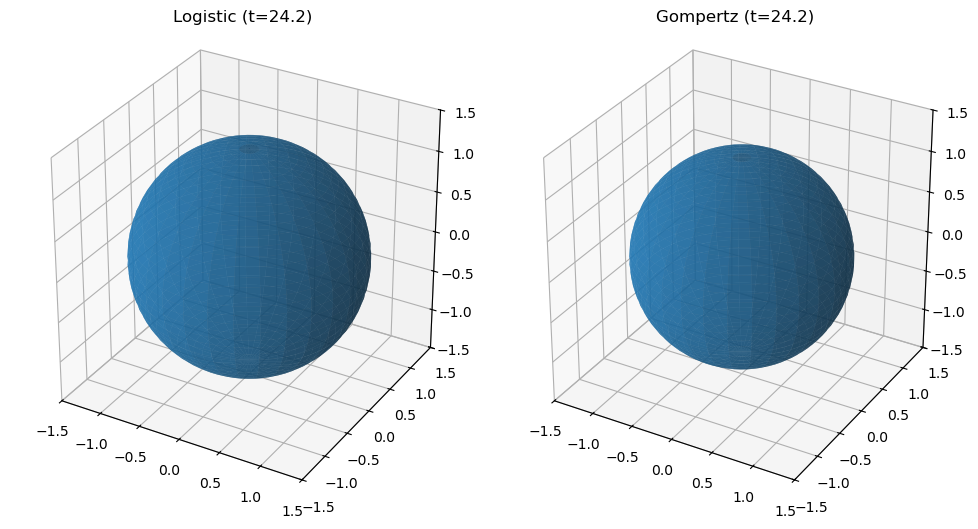

In [4]:
# Choose a time point
idx = 40

# Sphere coordinates
theta = np.linspace(0, np.pi, 40)
phi = np.linspace(0, 2*np.pi, 60)

theta, phi = np.meshgrid(theta, phi)

def sphere_coordinates(R):
    x = R * np.sin(theta) * np.cos(phi)
    y = R * np.sin(theta) * np.sin(phi)
    z = R * np.cos(theta)
    return x, y, z

fig = plt.figure(figsize=(10, 5))

for i, (name, R) in enumerate([
    ("Logistic", R_logistic[idx]),
    ("Gompertz", R_gompertz[idx])
]):
    ax = fig.add_subplot(1, 2, i+1, projection="3d")

    x, y, z = sphere_coordinates(R)
    ax.plot_surface(x, y, z, alpha=0.7)

    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-1.5, 1.5)
    ax.set_zlim(-1.5, 1.5)
    ax.set_box_aspect([1, 1, 1])

    ax.set_title(f"{name} (t={t[idx]:.1f})")

plt.tight_layout()
plt.show()

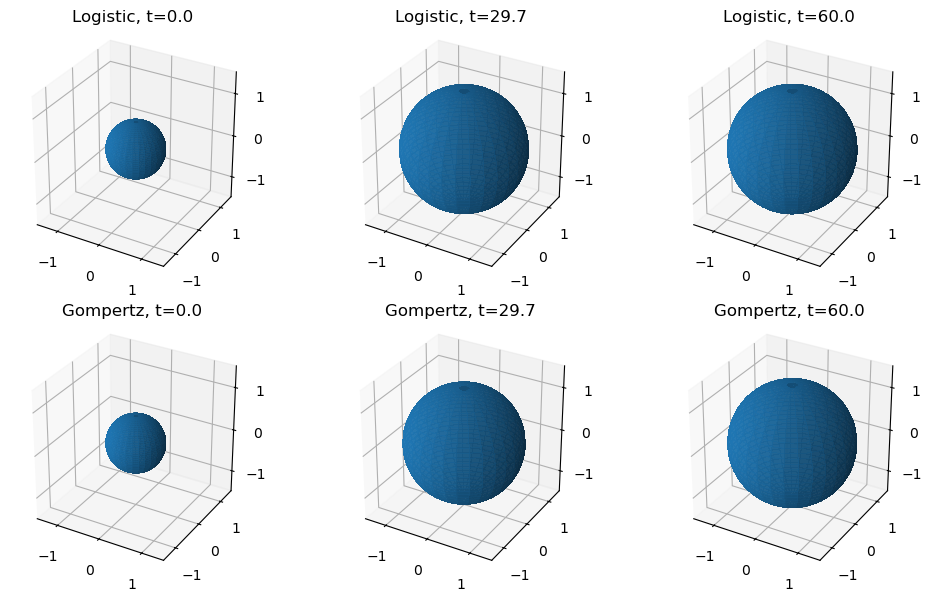

In [5]:
# Select three time points
time_points = [0, 30, 60]

fig = plt.figure(figsize=(12, 7))

for i, time in enumerate(time_points):

    idx = np.argmin(np.abs(t - time))

    for j, (name, R_values) in enumerate([
        ("Logistic", R_logistic),
        ("Gompertz", R_gompertz)
    ]):

        ax = fig.add_subplot(
            2, 3, j * 3 + i + 1,
            projection="3d"
        )

        R = R_values[idx]
        x, y, z = sphere_coordinates(R)

        ax.plot_surface(
            x, y, z,
            alpha=0.8,
            linewidth=0,
            antialiased=False
        )

        ax.set_xlim(-1.5, 1.5)
        ax.set_ylim(-1.5, 1.5)
        ax.set_zlim(-1.5, 1.5)

        ax.set_box_aspect([1, 1, 1])
        ax.set_title(f"{name}, t={t[idx]:.1f}")

plt.show()

In [6]:
# Compare tumor volumes
volume_diff = np.abs(V_logistic - V_gompertz)

# Find the time with maximum volume difference
idx_max = np.argmax(volume_diff)

print(f"Maximum difference at t = {t[idx_max]:.2f}")
print(f"Logistic volume = {V_logistic[idx_max]:.4f}")
print(f"Gompertz volume = {V_gompertz[idx_max]:.4f}")
print(f"Volume difference = {volume_diff[idx_max]:.4f}")

Maximum difference at t = 18.18
Logistic volume = 8.6332
Gompertz volume = 6.2212
Volume difference = 2.4121


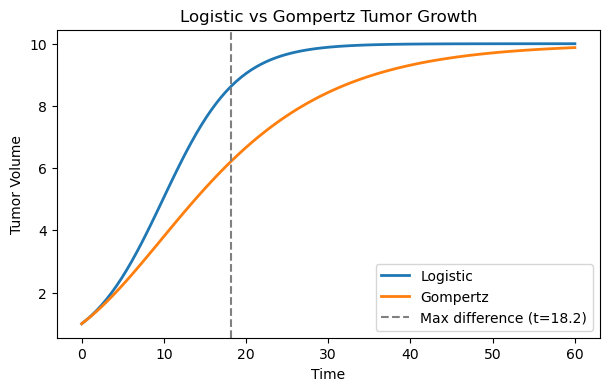

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(t, V_logistic, label="Logistic", linewidth=2)
ax.plot(t, V_gompertz, label="Gompertz", linewidth=2)

ax.axvline(
    t[idx_max],
    color="gray",
    linestyle="--",
    label=f"Max difference (t={t[idx_max]:.1f})"
)

ax.set_xlabel("Time")
ax.set_ylabel("Tumor Volume")
ax.set_title("Logistic vs Gompertz Tumor Growth")
ax.legend()

plt.show()

In [8]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Use fewer frames for faster rendering
frame_indices = np.linspace(0, len(t) - 1, 30, dtype=int)

fig = plt.figure(figsize=(10, 5))

axes = [
    fig.add_subplot(121, projection="3d"),
    fig.add_subplot(122, projection="3d")
]

models = [
    ("Logistic", R_logistic),
    ("Gompertz", R_gompertz)
]

def update(frame):
    idx = frame_indices[frame]

    for ax, (name, R_values) in zip(axes, models):
        ax.cla()

        x, y, z = sphere_coordinates(R_values[idx])

        ax.plot_surface(
            x, y, z,
            alpha=0.8,
            linewidth=0,
            antialiased=False
        )

        ax.set_xlim(-1.5, 1.5)
        ax.set_ylim(-1.5, 1.5)
        ax.set_zlim(-1.5, 1.5)
        ax.set_box_aspect([1, 1, 1])
        ax.set_title(f"{name}, t={t[idx]:.1f}")

    return []

ani = FuncAnimation(
    fig,
    update,
    frames=len(frame_indices),
    interval=150,
    blit=False
)

plt.close(fig)

HTML(ani.to_jshtml())

In [9]:
# Save animation as GIF
ani.save("tumor_growth.gif", writer="pillow", fps=7)

![Tumor Growth Animation](tumor_growth.gif)